# 04 · Training a blind DnCNN

**Day 3 · runs on Kaggle (GPU)** — start it in the morning.

Goal: train one colour DnCNN on Gaussian noise with σ sampled uniformly from [0, 55] ("blind": the model is
never told σ). It learns the **noise residual** $\hat v = f(y)$ and outputs $\hat x = y - \hat v$.

Reference: Zhang et al., *Beyond a Gaussian Denoiser: Residual Learning of Deep CNN for Image Denoising* (2017).

How to run it without babysitting:
1. Develop with `QUICK = True` (tiny run, a few minutes) until everything works.
2. Set `QUICK = False`, then **Save Version → Save & Run All (Commit)**. It runs in the background and the
   checkpoints land in the notebook's Output, which notebooks 05/06 can add as input.

> **Review checkpoint:** send me the notebook (with the QUICK run's outputs) *before* launching the long run —
> it's much cheaper to catch a bug then.

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("balraj98/berkeley-segmentation-dataset-500-bsds500")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500


In [2]:
import os, glob, math, time, random
from dataclasses import dataclass, asdict
import numpy as np
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

QUICK = False   # flip to False for the real (committed) run

BSD = "/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images"

@dataclass
class Config:
    train_dirs: tuple = (f"{BSD}/train", f"{BSD}/test")   # 400 images for training
    test_dir: str = f"{BSD}/val"                          # 100 images, NEVER trained on (contains CBSD68)
    out_dir:   str = "/kaggle/working"
    patch: int = 40
    stride: int = 20
    scales: tuple = (1.0, 0.9, 0.8, 0.7)
    channels: int = 3
    depth: int = 17          # DnCNN-S uses 17; the blind model in the paper uses 20 — your choice, justify it
    features: int = 64
    sigma_max: float = 55.0
    batch: int = 128
    epochs: int = 5 if QUICK else 50
    lr: float = 1e-3
    seed: int = 0

cfg = Config()
torch.manual_seed(cfg.seed); np.random.seed(cfg.seed); random.seed(cfg.seed)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, asdict(cfg))

cuda {'train_dirs': ('/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/train', '/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/test'), 'test_dir': '/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/val', 'out_dir': '/kaggle/working', 'patch': 40, 'stride': 20, 'scales': (1.0, 0.9, 0.8, 0.7), 'channels': 3, 'depth': 17, 'features': 64, 'sigma_max': 55.0, 'batch': 128, 'epochs': 50, 'lr': 0.001, 'seed': 0}


## 1 · Patch dataset

Extract overlapping patches once (multi-scale + flips/rotations), save to a single `.npy`, and load that.
Noise is added **on the fly** in `__getitem__`, so every epoch sees fresh noise.

In [3]:
IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif")

def list_images(folder):
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(folder) for f in fs if f.lower().endswith(IMG_EXTS))

def extract_patches(folder, patch, stride, scales, max_images=None):
    """Return uint8 array (num_patches, patch, patch, 3), RGB.

    For every image and every scale: resize, then slide a patch x patch window with step `stride`.
    Multi-scale = the model sees the same textures at several sizes (more variety from few images).
    Kept as uint8 (1 byte/value, 4x smaller than float32); converted to float in __getitem__.
    Augmentation (flips/rotations) is done on the fly in __getitem__, NOT here: storing all
    8 versions would make the array 8x bigger for no gain."""
    paths = list_images(folder)[:max_images]
    assert paths, f"no images found in {folder}"
    out = []
    for p in paths:
        img = cv2.imread(p, cv2.IMREAD_COLOR)[:, :, ::-1]               # BGR -> RGB, uint8
        h, w = img.shape[:2]
        for s in scales:
            hs, ws = int(h * s), int(w * s)
            if min(hs, ws) < patch:
                continue
            im = img if s == 1.0 else cv2.resize(img, (ws, hs), interpolation=cv2.INTER_CUBIC)
            # All windows at once (no Python loop over positions):
            # sliding_window_view gives shape (H-patch+1, W-patch+1, 3, patch, patch); keep every `stride`-th
            win = np.lib.stride_tricks.sliding_window_view(im, (patch, patch), axis=(0, 1))[::stride, ::stride]
            win = win.transpose(0, 1, 3, 4, 2).reshape(-1, patch, patch, 3)  # -> (n, patch, patch, 3)
            out.append(np.ascontiguousarray(win))
    patches = np.concatenate(out)
    print(f"{len(paths)} images x {len(scales)} scales -> {len(patches):,} patches "
          f"({patches.nbytes / 1e9:.2f} GB as uint8)")
    return patches

def augment(p, k):
    """One of the 8 dihedral transforms (4 rotations x optional flip), k in 0..7. Works on (H, W, C)."""
    p = np.rot90(p, k % 4, axes=(0, 1))
    return p[:, ::-1] if k >= 4 else p

def check_no_overlap(train_dir, test_dir):
    """Training on test images would inflate every result. Check by file name AND by pixel content."""
    import hashlib
    name = lambda p: os.path.splitext(os.path.basename(p))[0]
    digest = lambda p: hashlib.md5(cv2.imread(p).tobytes()).hexdigest()
    tr, te = list_images(train_dir), list_images(test_dir)
    same_names = {name(p) for p in tr} & {name(p) for p in te}
    same_pixels = {digest(p) for p in tr} & {digest(p) for p in te}
    print(f"train {len(tr)} images, test {len(te)} images: "
          f"{len(same_names)} shared names, {len(same_pixels)} identical images")
    return same_names, same_pixels

In [4]:
# 1. Make sure no test (val) image is in the training folders
for d in cfg.train_dirs:
    check_no_overlap(d, cfg.test_dir)        # want: 0 shared names, 0 identical images, for both folders

# 2. Patches from BOTH training folders, joined into one array
#    (extract_patches takes ONE folder, so call it once per folder and concatenate)
patches = np.concatenate([
    extract_patches(d, cfg.patch, cfg.stride, cfg.scales, max_images=25 if QUICK else None)
    for d in cfg.train_dirs
])
print(f"total: {len(patches):,} patches ({patches.nbytes / 1e9:.2f} GB as uint8)")

train 200 images, test 100 images: 0 shared names, 0 identical images
train 200 images, test 100 images: 0 shared names, 0 identical images
200 images x 4 scales -> 190,600 patches (0.91 GB as uint8)
200 images x 4 scales -> 190,600 patches (0.91 GB as uint8)
total: 381,200 patches (1.83 GB as uint8)


noise std over 2000 items: mean 26.2 (about 27.5, a bit less with clipping), min 0.0, max 53.4 (about 55.0)


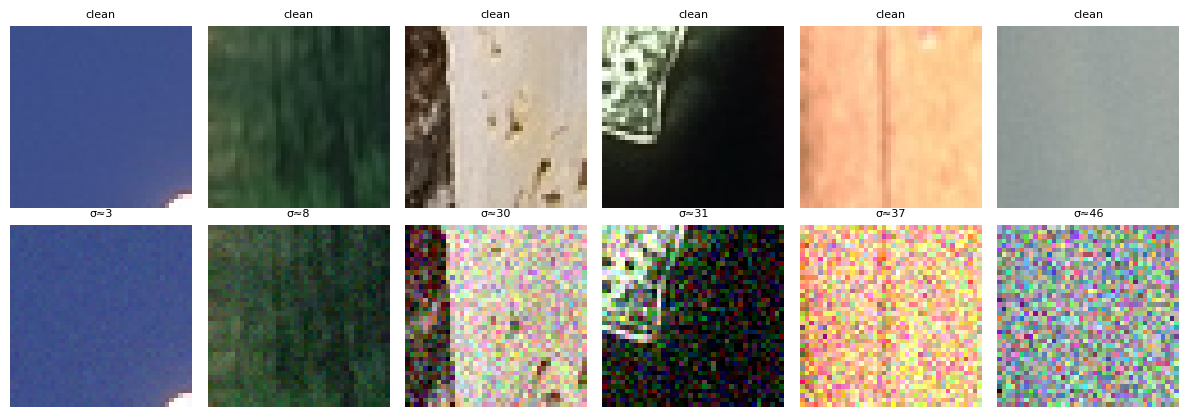

batch shapes: [torch.Size([128, 3, 40, 40]), torch.Size([128, 3, 40, 40]), torch.Size([128, 3, 40, 40])]
predict-zero loss: 0.01371  (the training loss must end well below this)


In [5]:
class NoisyPatches(Dataset):
    """Clean uint8 patches -> (noisy, noise, clean) float tensors (3, H, W) in [0, 1].
    Fresh noise (and a fresh random flip/rotation) every time an item is loaded, so every epoch
    sees new training pairs from the same patches."""

    def __init__(self, patches, sigma_max, augment_data=True, clip=True):
        self.p = patches                  # (N, H, W, 3) uint8, from extract_patches
        self.sigma_max = sigma_max        # on the 0-255 scale (55 -> blind model for sigma in [0, 55])
        self.augment_data = augment_data
        self.clip = clip                  # True = match the test pipeline (degrade() clips); see notes

    def __len__(self):
        return len(self.p)

    def __getitem__(self, i):
        p = self.p[i]
        if self.augment_data:
            k = int(torch.randint(8, (1,)))                  # torch RNG: seeded separately in each worker
            p = np.ascontiguousarray(augment(p, k))          # rot90/flip give negative strides; torch needs contiguous
        clean = torch.from_numpy(p).permute(2, 0, 1).float() / 255.0      # (3, H, W), [0, 1]

        sigma = torch.rand(1) * self.sigma_max / 255.0       # one sigma per patch, ~ U(0, sigma_max) -> "blind"
        noisy = clean + sigma * torch.randn_like(clean)
        if self.clip:
            noisy = noisy.clamp(0, 1)
        noise = noisy - clean                                # residual target, computed AFTER clipping
        return noisy, noise, clean


# --- sanity checks: run once, before training -------------------------------------------------
ds = NoisyPatches(patches, cfg.sigma_max)
noisy, noise, clean = ds[0]
assert noisy.shape == (3, cfg.patch, cfg.patch) and noisy.dtype == torch.float32
assert torch.allclose(noisy - noise, clean, atol=1e-6), "noisy - noise must equal clean exactly"
assert 0 <= clean.min() and clean.max() <= 1

stds = torch.stack([ds[int(j)][1].std() for j in torch.randint(len(ds), (2000,))]) * 255
print(f"noise std over 2000 items: mean {stds.mean():.1f} (about {cfg.sigma_max / 2:.1f}, a bit less with clipping), "
      f"min {stds.min():.1f}, max {stds.max():.1f} (about {cfg.sigma_max})")

# Visual: 6 random pairs, sorted from least to most noisy
import matplotlib.pyplot as plt
items = sorted((ds[int(j)] for j in torch.randint(len(ds), (6,))), key=lambda t: t[1].std())
fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
for c, (n_, v_, cl_) in enumerate(items):
    axes[0, c].imshow(cl_.permute(1, 2, 0)); axes[0, c].set_title("clean", fontsize=8)
    axes[1, c].imshow(n_.clamp(0, 1).permute(1, 2, 0)); axes[1, c].set_title(f"σ≈{v_.std() * 255:.0f}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

loader = DataLoader(ds, batch_size=cfg.batch, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
b = next(iter(loader))
print("batch shapes:", [t.shape for t in b])     # 3 x (128, 3, 40, 40)

# The number to beat: a model that always predicts "no noise" scores the average noise power
base = np.mean([(b_[1] ** 2).mean().item() for b_, _ in zip(loader, range(20))])
print(f"predict-zero loss: {base:.5f}  (the training loss must end well below this)")

## 2 · Model

Layer 1: Conv(3×3) + ReLU. Layers 2…D−1: Conv(3×3, no bias) + BatchNorm + ReLU. Layer D: Conv(3×3) to `channels`.
All convolutions use padding 1 so the output is the same size as the input.

**Write-up prompt:** why predict the residual instead of the clean image? (Think about what's easier to
learn when the noise is small and when the identity map is nearly right.)

In [6]:
class DnCNN(nn.Module):
    def __init__(self, channels=3, depth=17, features=64):
        super().__init__()
        layers = [nn.Conv2d(channels, features, kernel_size=3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False),
                       nn.BatchNorm2d(features),
                       nn.ReLU(inplace=True)]
        layers += [nn.Conv2d(features, channels, kernel_size=3, padding=1)]
        self.body = nn.Sequential(*layers)

    def forward(self, y):
        return self.body(y)          # predicted NOISE (residual); the clean estimate is y - self(y)

In [7]:
model = DnCNN(cfg.channels, cfg.depth, cfg.features).to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

558403 parameters


## 3 · Training loop (mixed precision, checkpoints, resume)

In [8]:
opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[int(cfg.epochs * 0.6), int(cfg.epochs * 0.85)], gamma=0.1)
scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
CKPT = os.path.join(cfg.out_dir, "dncnn_quick.pt" if QUICK else "dncnn_last.pt")   # QUICK never resumes into the real run

start_epoch, history = 0, []
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device, weights_only=False)   # our own file
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    start_epoch, history = ck["epoch"] + 1, ck["history"]
    print("resumed from epoch", start_epoch)

for epoch in range(start_epoch, cfg.epochs):
    model.train(); t0 = time.time(); running = 0.0
    for noisy, noise, clean in loader:
        noisy, noise = noisy.to(device, non_blocking=True), noise.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            pred = model(noisy)
            loss = torch.nn.functional.mse_loss(pred.float(), noise)  # done: residual loss — the paper uses 1/2N * ||f(y) - v||^2; plain MSE is fine, say which
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        running += loss.item()
    sched.step()
    history.append(running / len(loader))
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    epoch=epoch, history=history, cfg=asdict(cfg)), CKPT)
    # loss = MSE of the restored image, so 10*log10(1/loss) is the average training PSNR
    print(f"epoch {epoch:3d}  loss {history[-1]:.5f}  (predict-zero {base:.5f}, ~{10 * math.log10(1 / history[-1]):.1f} dB)  "
          f"{time.time() - t0:.0f}s")

epoch   0  loss 0.00548  (predict-zero 0.01371, ~22.6 dB)  267s
epoch   1  loss 0.00163  (predict-zero 0.01371, ~27.9 dB)  273s
epoch   2  loss 0.00139  (predict-zero 0.01371, ~28.6 dB)  274s
epoch   3  loss 0.00130  (predict-zero 0.01371, ~28.9 dB)  274s
epoch   4  loss 0.00124  (predict-zero 0.01371, ~29.1 dB)  275s
epoch   5  loss 0.00120  (predict-zero 0.01371, ~29.2 dB)  275s
epoch   6  loss 0.00118  (predict-zero 0.01371, ~29.3 dB)  275s
epoch   7  loss 0.00119  (predict-zero 0.01371, ~29.2 dB)  274s
epoch   8  loss 0.00115  (predict-zero 0.01371, ~29.4 dB)  274s
epoch   9  loss 0.00114  (predict-zero 0.01371, ~29.4 dB)  275s
epoch  10  loss 0.00113  (predict-zero 0.01371, ~29.5 dB)  275s
epoch  11  loss 0.00113  (predict-zero 0.01371, ~29.5 dB)  275s
epoch  12  loss 0.00111  (predict-zero 0.01371, ~29.5 dB)  275s
epoch  13  loss 0.00111  (predict-zero 0.01371, ~29.6 dB)  274s
epoch  14  loss 0.00110  (predict-zero 0.01371, ~29.6 dB)  274s
epoch  15  loss 0.00110  (predict-zero 0

## 4 · Evaluation on the colour test set

Report PSNR/SSIM at σ = 15, 25, 50 next to your best classical filter from notebook 01, and do a sanity check
against the DnCNN paper's tables (they report grayscale *and* colour results; compare with the matching one).
Also test σ values **outside** training (e.g. 65, 75): what happens to a blind model past its range?

       psnr_noisy  psnr_dncnn  ssim_noisy  ssim_dncnn  gain_db
sigma                                                         
15         24.821      33.755       0.600       0.931     8.93
25         20.526      31.047       0.424       0.882    10.52
50         14.997      27.686       0.220       0.778    12.69
65         13.087      26.159       0.163       0.720    13.07
75         12.114      24.561       0.137       0.637    12.45


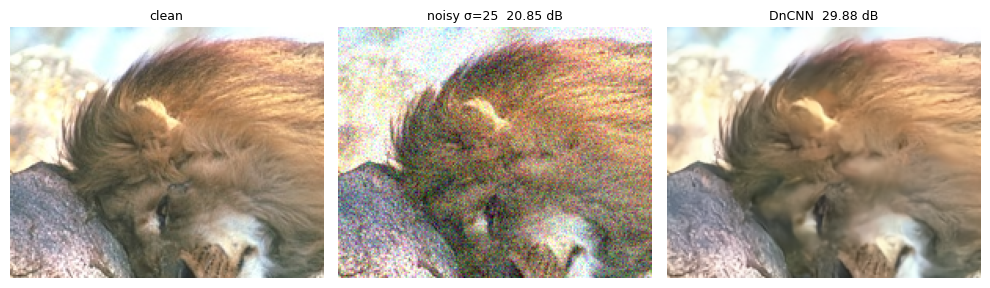

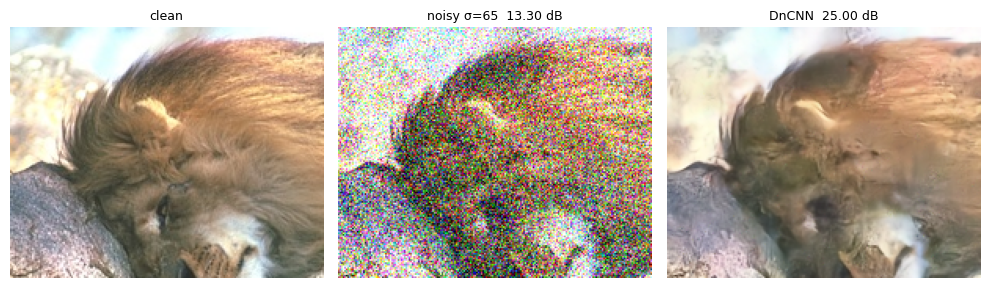

In [9]:
# Section 4 · Evaluation on the BSD500 val set (contains CBSD68), paired with notebook 01 (same test images, same noise)
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio as sk_psnr, structural_similarity

@torch.no_grad()
def denoise(model, img):
    """img: float32 RGB (H, W, 3) in [0, 1] -> denoised image, same format."""
    model.eval()                                                    # BatchNorm uses its running stats
    y = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).unsqueeze(0).to(device)
    with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
        v = model(y).float()                                        # predicted noise
    return (y - v).clamp(0, 1)[0].permute(1, 2, 0).cpu().numpy().astype(np.float32)

def load_rgb(p):
    return cv2.imread(p, cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32) / 255.0

test_paths = list_images(cfg.test_dir)
assert len(test_paths) == 100, f"expected the 100 BSD500 val images, found {len(test_paths)}"
test_imgs = [load_rgb(p) for p in test_paths][4:]                 # same split as notebook 01: first 4 were for tuning
if QUICK:
    test_imgs = test_imgs[:5]

# Noise identical to notebook 01's degrade(clean, "gaussian", sigma, noise_rng(i, "gaussian", si)),
# so DnCNN and the classical filters are compared on exactly the same noisy images
NB01_LEVELS, GAUSS_IDX = [5, 15, 25, 35, 50], 0
def noisy_like_nb01(clean, i, sigma):
    sev = NB01_LEVELS.index(sigma) if sigma in NB01_LEVELS else 100 + int(sigma)   # 65, 75: outside training
    rng = np.random.default_rng([0, i, GAUSS_IDX, sev])
    return np.clip(clean + rng.normal(0, sigma / 255, clean.shape), 0, 1).astype(np.float32)

SIGMAS = [15, 25, 50, 65, 75]
rows = []
for s in SIGMAS:
    for i, clean in enumerate(test_imgs):
        noisy = noisy_like_nb01(clean, i, s)
        out = denoise(model, noisy)
        rows.append(dict(sigma=s, image=i,
                         psnr_noisy=sk_psnr(clean, noisy, data_range=1.0), psnr_dncnn=sk_psnr(clean, out, data_range=1.0),
                         ssim_noisy=structural_similarity(clean, noisy, channel_axis=-1, data_range=1.0),
                         ssim_dncnn=structural_similarity(clean, out, channel_axis=-1, data_range=1.0)))
res = pd.DataFrame(rows)
res.to_csv(os.path.join(cfg.out_dir, "dncnn_eval.csv"), index=False)
summary = res.groupby("sigma")[["psnr_noisy", "psnr_dncnn", "ssim_noisy", "ssim_dncnn"]].mean().round(3)
summary["gain_db"] = (summary.psnr_dncnn - summary.psnr_noisy).round(2)
print(summary)
# Sanity: the DnCNN paper reports about 33.9 / 31.2 / 27.9 dB for colour CBSD68 (68 of these 100) at sigma 15 / 25 / 50
# (CDnCNN-B, unclipped noise). Expect to land below that: shorter training, clipped noise, 17 layers.

# Visual crops: sigma 25 (inside the training range) and 65 (outside it)
for s in (25, 65):
    clean = test_imgs[0]; noisy = noisy_like_nb01(clean, 0, s); out = denoise(model, noisy)
    r0, r1, c0, c1 = 60, 220, 120, 320
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    for ax, im, t in zip(axes, [clean, noisy, out],
                         ["clean", f"noisy σ={s}  {sk_psnr(clean, noisy, data_range=1):.2f} dB",
                          f"DnCNN  {sk_psnr(clean, out, data_range=1):.2f} dB"]):
        ax.imshow(im[r0:r1, c0:c1]); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(cfg.out_dir, f"dncnn_crop_sigma{s}.png"), dpi=150); plt.show()

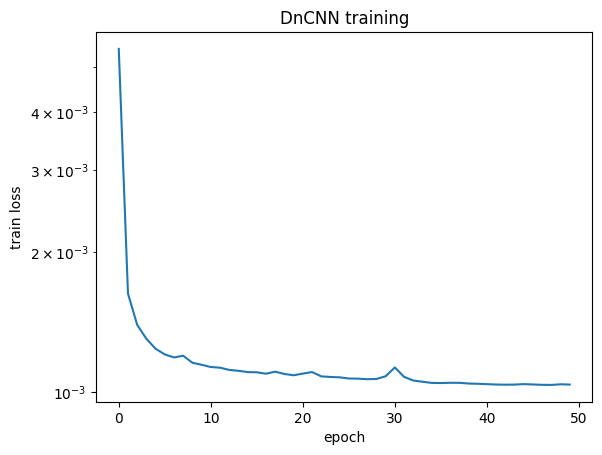

In [10]:
import matplotlib.pyplot as plt
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("train loss"); plt.yscale("log"); plt.title("DnCNN training")
plt.savefig(os.path.join(cfg.out_dir, "loss.png"), dpi=150); plt.show()

## 5 · (Day 7 stretch) Second model for JPEG artifacts

Copy this notebook, swap the on-the-fly noise for JPEG compression at a random quality in [10, 90]
(`degradations.jpeg_compress`), and the target residual becomes `compressed − clean`. Same architecture,
same loop — a nice demonstration that the *training data* defines what "restoration" means.